In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv('Customer_Churn.csv')

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
df_imp=df[['tenure','MonthlyCharges','Contract','InternetService','PaymentMethod','TechSupport','OnlineSecurity','Churn']]

In [5]:
df_imp.head()

,tenure,MonthlyCharges,Contract,InternetService,PaymentMethod,TechSupport,OnlineSecurity,Churn
0,1,29.85,Month-to-month,DSL,Electronic check,No,No,No
1,34,56.95,One year,DSL,Mailed check,No,Yes,No
2,2,53.85,Month-to-month,DSL,Mailed check,No,Yes,Yes
3,45,42.30,One year,DSL,Bank transfer (automatic),Yes,Yes,No
4,2,70.70,Month-to-month,Fiber optic,Electronic check,No,No,Yes


In [7]:
df_imp.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   tenure           7043 non-null   int64  
 1   MonthlyCharges   7043 non-null   float64
 2   Contract         7043 non-null   str    
 3   InternetService  7043 non-null   str    
 4   PaymentMethod    7043 non-null   str    
 5   TechSupport      7043 non-null   str    
 6   OnlineSecurity   7043 non-null   str    
 7   Churn            7043 non-null   str    
dtypes: float64(1), int64(1), str(6)
memory usage: 440.3 KB


In [14]:
df['OnlineSecurity'].value_counts()

OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

# Univariate Analysis

In [15]:
categorical_features=df_imp.select_dtypes(include=['str']).columns
numerical_features=df_imp.select_dtypes(exclude=['str']).columns

In [82]:
categorical_features=categorical_features.drop('Churn')

### Numerical Features

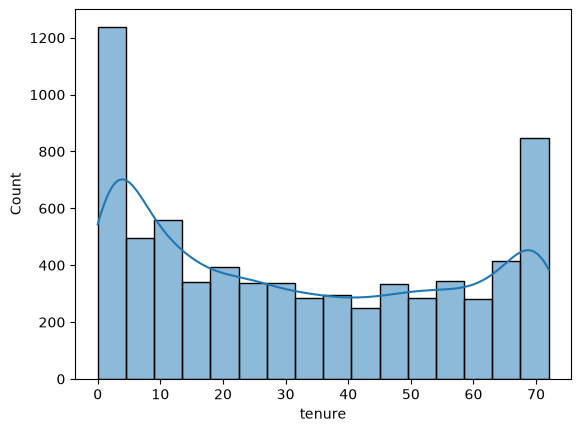

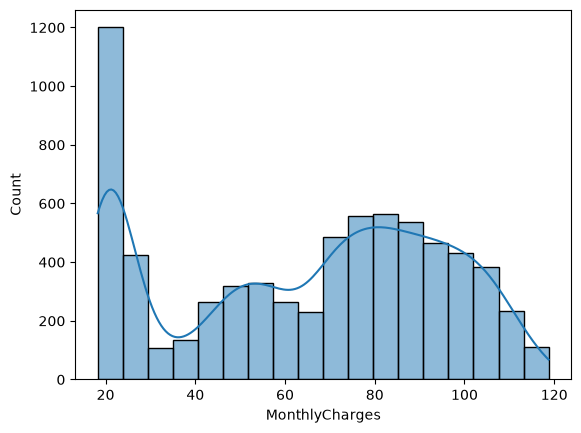

In [84]:
for col in numerical_features:
    sns.histplot(data=df_imp,x=col,kde=True)
    plt.show()

### Categorical Features

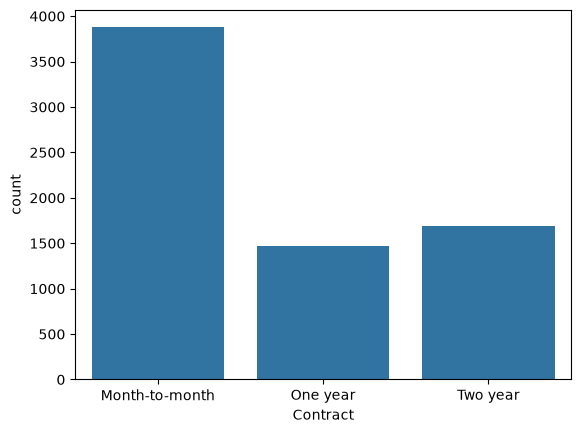

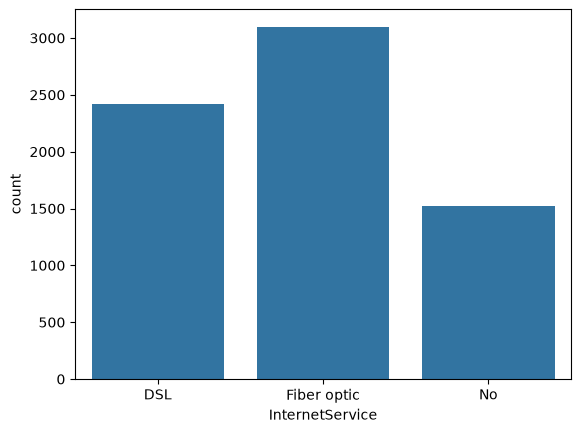

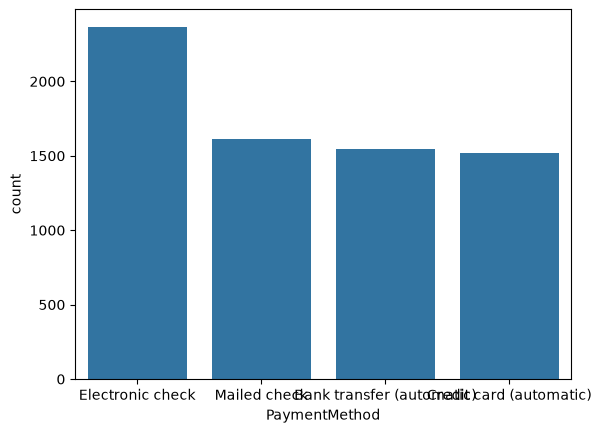

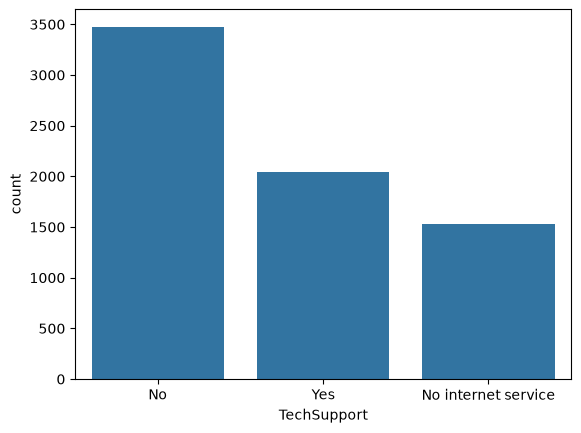

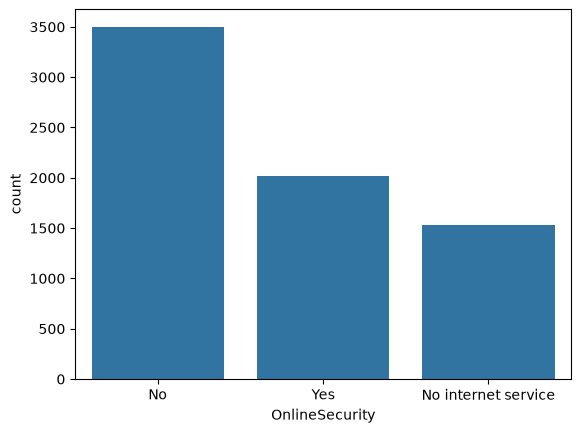

In [85]:
for col in categorical_features:
    sns.countplot(data=df_imp,x=col)
    plt.show()

### Let's check their impact with respect to Target

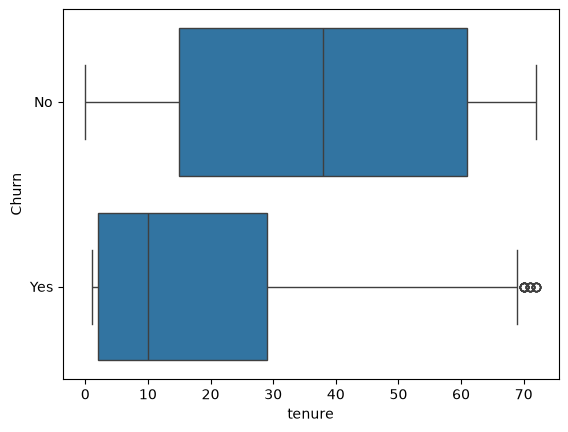

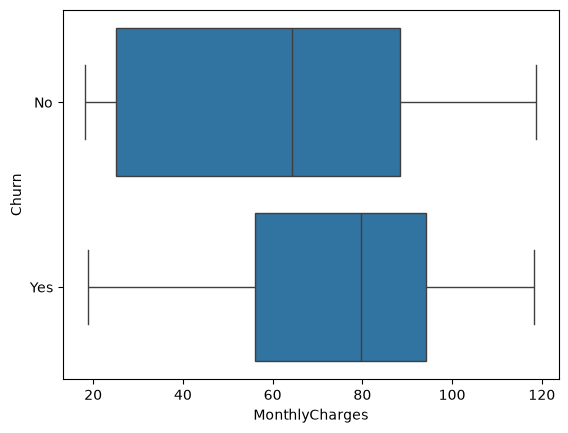

In [20]:
for col in numerical_features:
    sns.boxplot(data=df_imp,x=col,y='Churn')
    plt.show()

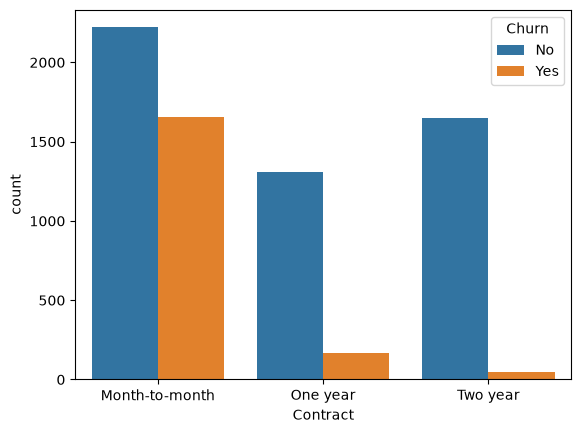

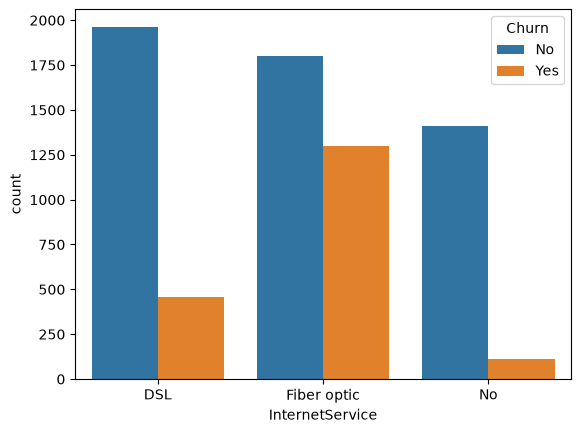

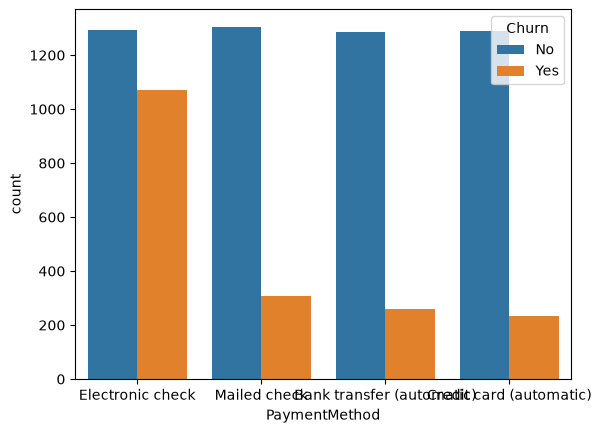

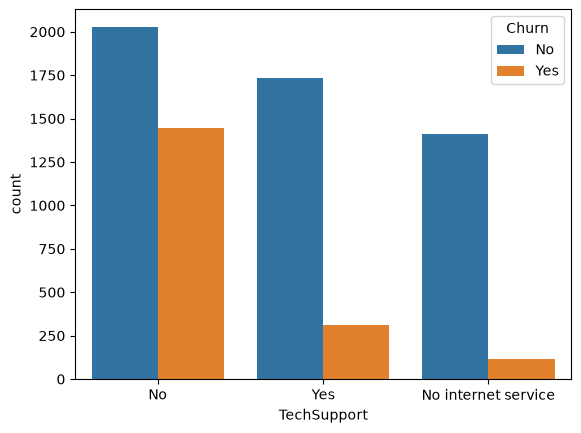

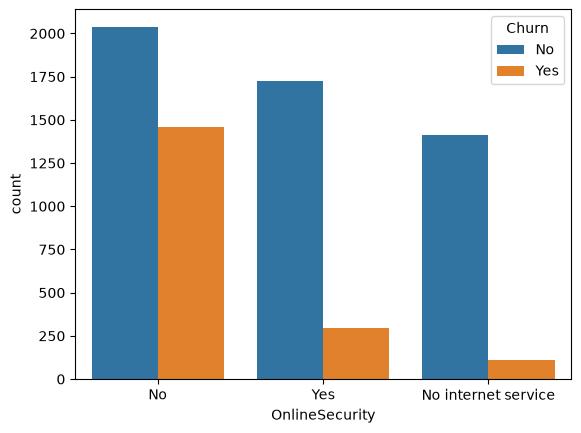

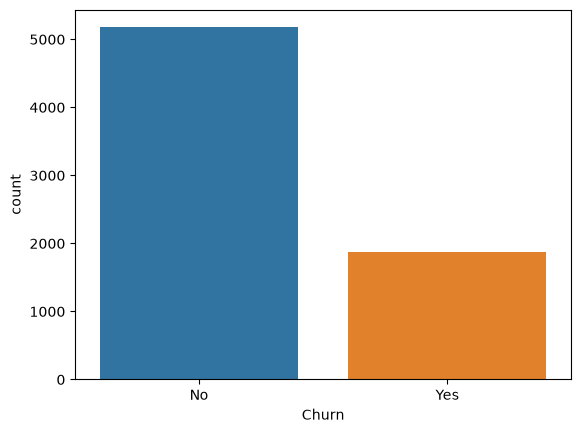

In [22]:
for col in categorical_features:
    sns.countplot(data=df_imp,x=col,hue='Churn')
    plt.show()

In [90]:
for col in categorical_features:
    print(pd.crosstab(df_imp[col],df_imp['Churn'],normalize='index')*100,end='\n\n\n')

Churn                   0          1
Contract                            
Month-to-month  57.290323  42.709677
One year        88.730482  11.269518
Two year        97.168142   2.831858


Churn                    0          1
InternetService                      
DSL              81.040892  18.959108
Fiber optic      58.107235  41.892765
No               92.595020   7.404980


Churn                              0          1
PaymentMethod                                  
Bank transfer (automatic)  83.290155  16.709845
Credit card (automatic)    84.756899  15.243101
Electronic check           54.714588  45.285412
Mailed check               80.893300  19.106700


Churn                        0          1
TechSupport                              
No                   58.364526  41.635474
No internet service  92.595020   7.404980
Yes                  84.833659  15.166341


Churn                        0          1
OnlineSecurity                           
No                   58.233276  41.

In [35]:
df_imp.head()
df_imp['Churn']=df_imp['Churn'].apply(lambda x: 1 if x=='Yes' else 0)

# Model 1

In [37]:
from sklearn.model_selection import train_test_split

X=df_imp.drop(columns='Churn')
y=df_imp['Churn']

In [50]:
X_encoded=pd.get_dummies(X,drop_first=True).astype(int)

In [52]:
X_train,X_test,y_train,y_test=train_test_split(X_encoded,y,stratify=y,random_state=42, test_size=0.2)

In [71]:
from sklearn.tree import DecisionTreeClassifier,plot_tree

model=DecisionTreeClassifier(max_depth=4,random_state=42,min_samples_leaf=10)
model.fit(X_train,y_train)
y_pred=model.predict(X_test)

In [78]:
from sklearn.metrics import f1_score, accuracy_score, recall_score, precision_score,confusion_matrix

f1=f1_score(y_test, y_pred)
recall=recall_score(y_test, y_pred)
precision=precision_score(y_test, y_pred)
cm=confusion_matrix(y_test, y_pred)
accuracy=accuracy_score(y_pred,y_test)

print('CM: ',cm)
print('F1_Score: ',f1)
print('Precision_Score: ',precision)
print('Recall_Score: ',recall)
print('Accuracy_Score: ',accuracy)



CM:  [[929 106]
 [182 192]]
F1_Score:  0.5714285714285714
Precision_Score:  0.6442953020134228
Recall_Score:  0.5133689839572193
Accuracy_Score:  0.7955997161107168


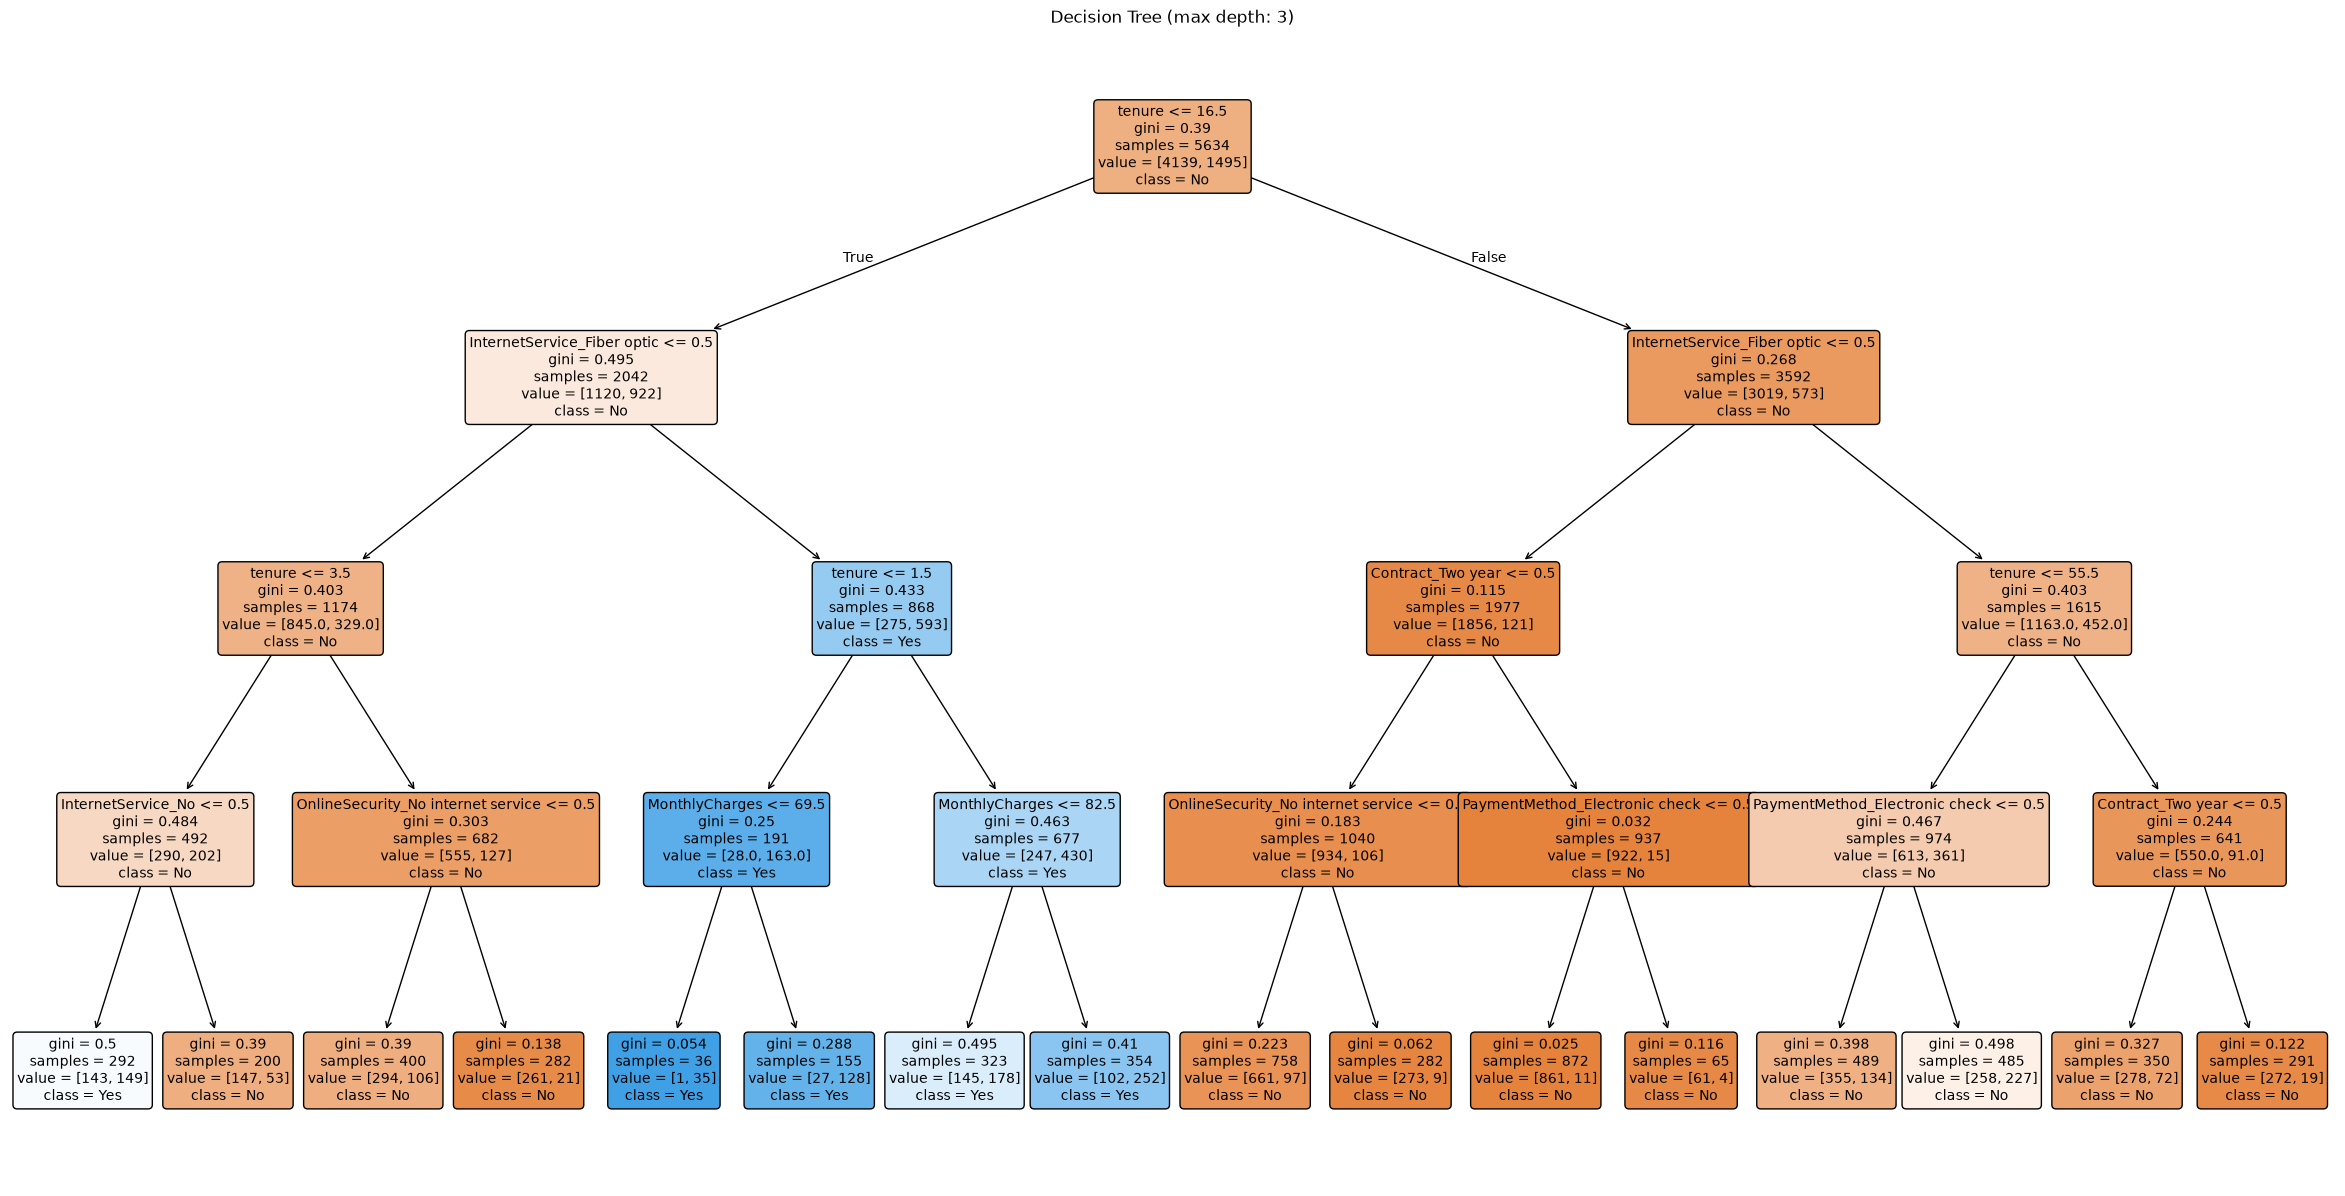

In [76]:
fig,ax=plt.subplots(figsize=(30,15))

plot_tree(
    model,
    feature_names=X_encoded.columns,
    class_names=['No','Yes'],
    filled=True,rounded=True,fontsize=10,ax=ax
)

ax.set_title('Decision Tree (max depth: 3)')
plt.show()

# Model 2

In [144]:
X_train2,X_test2,y_train2,y_test2=train_test_split(X,y,stratify=y,random_state=42,test_size=0.2)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor=ColumnTransformer(
    transformers=[('OHC',OneHotEncoder(sparse_output=False,handle_unknown='ignore'),categorical_features)], remainder='passthrough'
)

In [145]:
from sklearn.model_selection import train_test_split

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train2, y_train2,
    test_size=0.2,
    random_state=42,
    stratify=y_train2
)

depths = range(1, 11)
f1s = []

for d in depths:
    model = Pipeline([
    ('preprocessor',preprocessor),
    ('classifier',DecisionTreeClassifier(max_depth=d,random_state=42,min_samples_leaf=10))
])

    model.fit(X_tr, y_tr)

    y_pred = model.predict(X_val)

    f1 = f1_score(y_val, y_pred, zero_division=0)
    f1s.append(f1)

best_depth = depths[f1s.index(max(f1s))]

print("Best Depth:", best_depth)
print("Best Validation Precision:", max(f1s))

Best Depth: 2
Best Validation Precision: 0.5891472868217055


In [146]:
from sklearn.pipeline import Pipeline

model2=Pipeline([
    ('preprocessor',preprocessor),
    ('classifier',DecisionTreeClassifier(max_depth=2,random_state=42,min_samples_leaf=10))
])
model2.fit(X_train2,y_train2)
y_pred2=model2.predict(X_test2)

In [147]:
f1=f1_score(y_test2, y_pred2)
recall=recall_score(y_test2, y_pred2)
precision=precision_score(y_test2, y_pred2)
cm=confusion_matrix(y_test2, y_pred2)
accuracy=accuracy_score(y_pred2,y_test2)

print('CM: ',cm)
print('F1_Score: ',f1)
print('Precision_Score: ',precision)
print('Recall_Score: ',recall)
print('Accuracy_Score: ',accuracy)


CM:  [[836 199]
 [152 222]]
F1_Score:  0.5584905660377358
Precision_Score:  0.5273159144893111
Recall_Score:  0.5935828877005348
Accuracy_Score:  0.7508871540099361


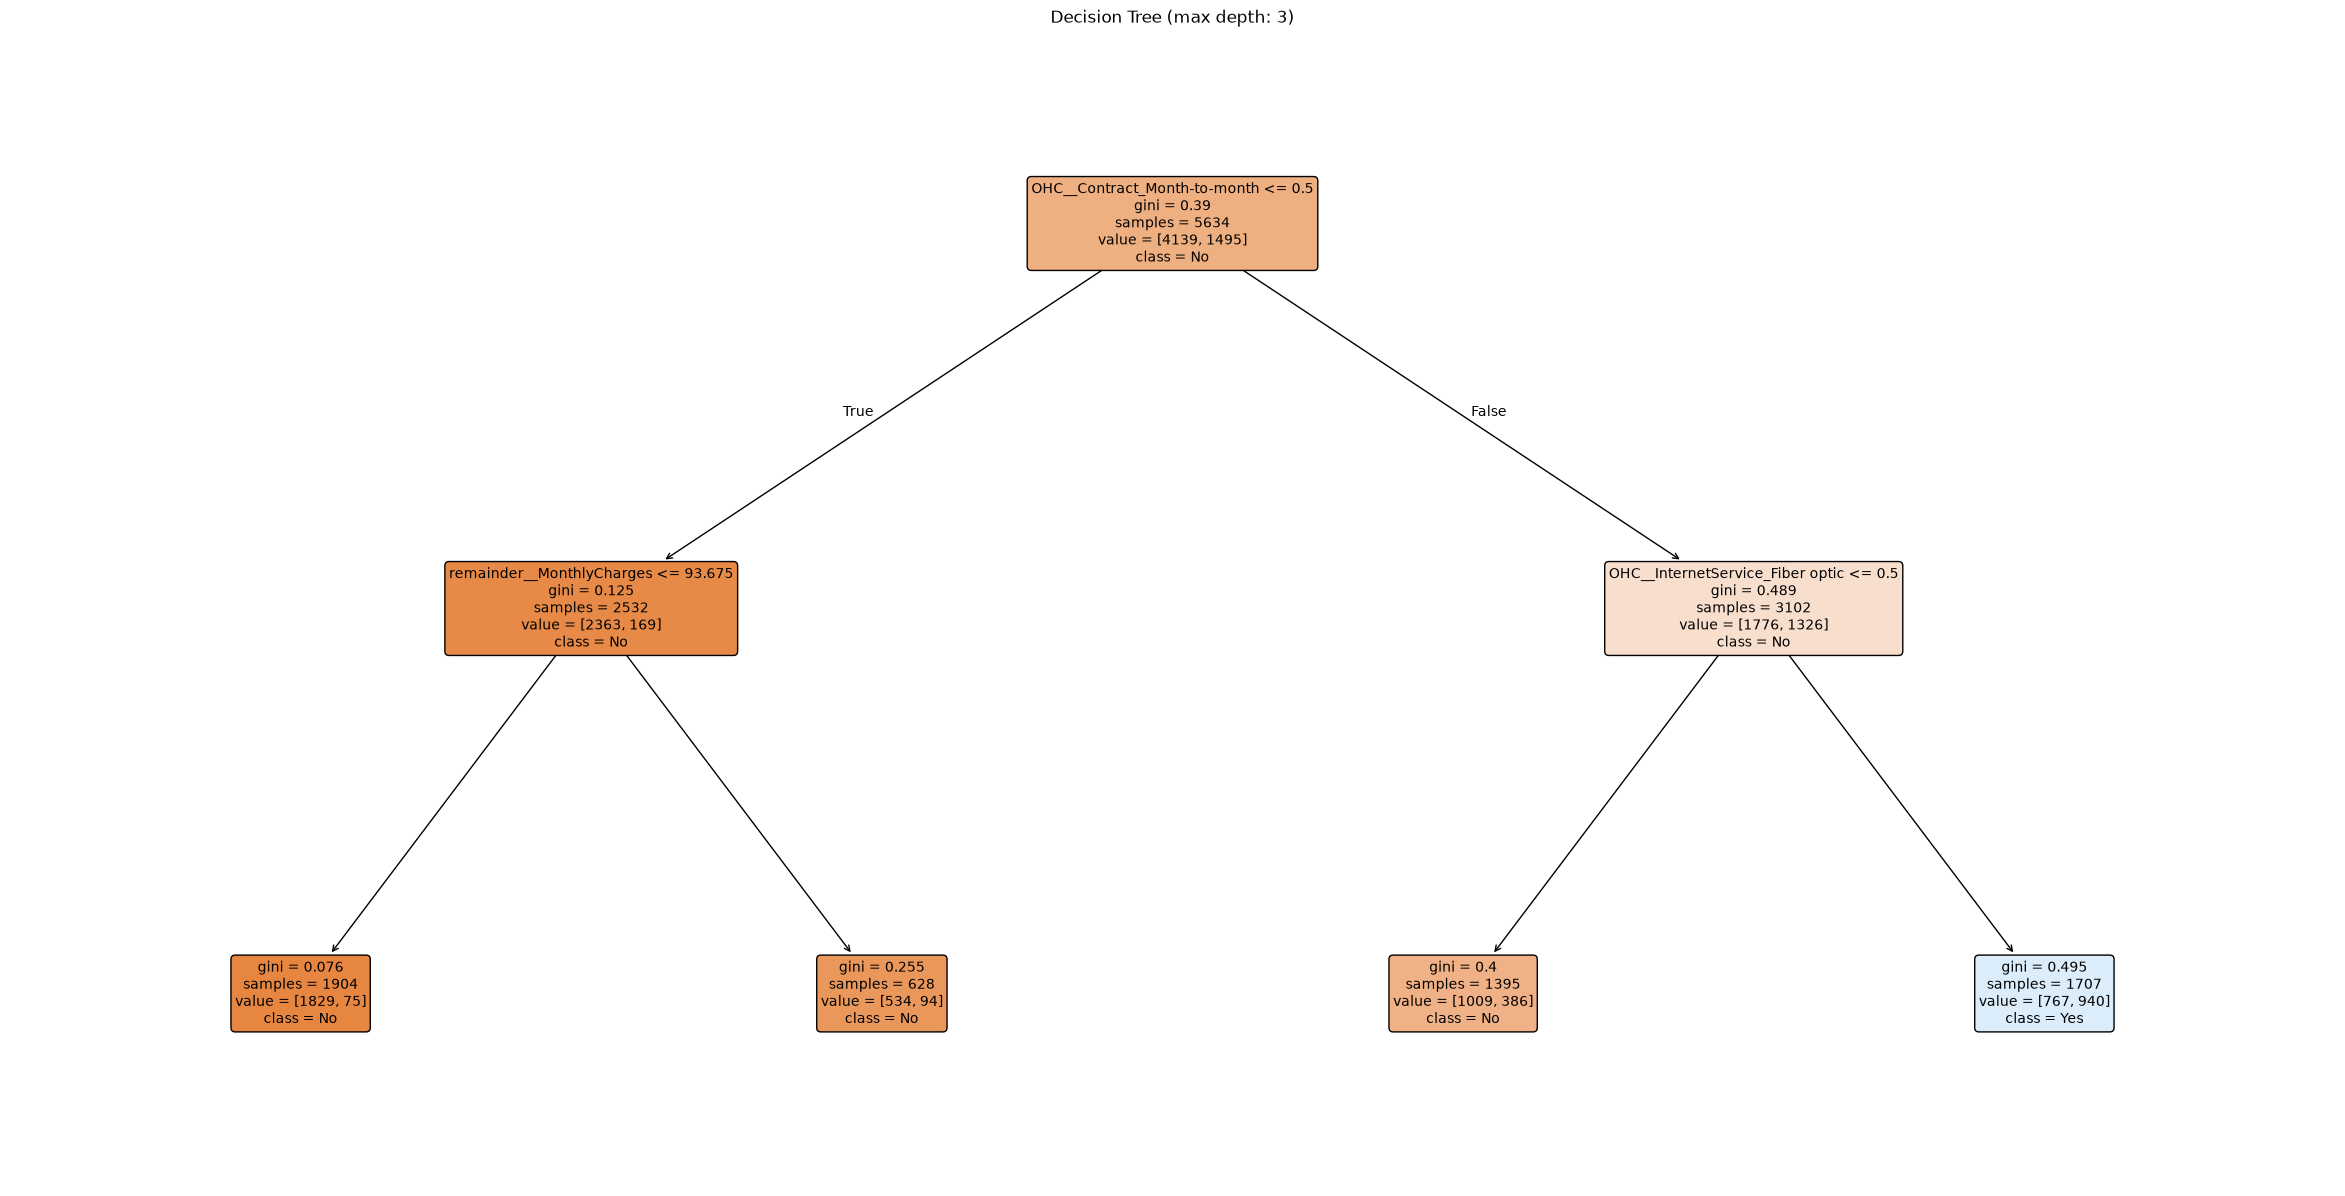

In [148]:
fig, ax = plt.subplots(figsize=(30, 15))

plot_tree(
    model2.named_steps['classifier'],
    feature_names=model2.named_steps['preprocessor'].get_feature_names_out(),
    class_names=['No', 'Yes'],
    filled=True, rounded=True, fontsize=10, ax=ax
)

ax.set_title('Decision Tree (max depth: 3)')
plt.show()

In [149]:
import joblib

joblib.dump(model2,'customer_churn_model.pkl')

['customer_churn_model.pkl']